# Figuras del objetivo específico 2 (1,000 correos)

Genera únicamente las figuras para la tesis, con los mismos datos que `evaluacion_objetivo_2.ipynb`:
los 1,000 correos de `eval_external.csv` (500 phishing, 500 legítimos).

- **Coeficiente:** similitud coseno entre el correo y el centroide del arquetipo que le asigna KMeans, tomada
  de `eval_system/arquetipo_similitud_recalculada.csv` (recalculada con el modelo y los centroides del servidor
  de arquetipos; no se llama al LLM ni a VirusTotal).
- **Arquetipo:** el asignado por KMeans en ese mismo recalculo. Todo correo recibe uno, también los legítimos.
- **Detección (TP y FN):** clasificación del modo explicación (`results_explicacion_1000.jsonl`).

Formato: 300 dpi, fuente de 11 pt, sin título dentro de la figura (va en el *caption* de LaTeX) y colores
distinguibles con daltonismo. Las figuras se guardan en `experiments/figures/arquetipos_objetivo2/`.

In [1]:
import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score, roc_curve

SEMILLA = 42
COLOR_PHISHING, COLOR_LEGITIMO = "#c44e52", "#4c72b0"
GRIS = "#4d4d4d"

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "font.family": "sans-serif",
})

# Carpeta experiments/ (funciona si el notebook se ejecuta desde experiments/ o desde la raíz del repo)
BASE = Path.cwd() if (Path.cwd() / "eval_system").exists() else Path.cwd() / "experiments"
RUTA_SIMILITUD = BASE / "eval_system" / "arquetipo_similitud_recalculada.csv"
RUTA_EXPLICACION = BASE / "eval_system" / "results_explicacion_1000.jsonl"
FIG_DIR = BASE / "figures" / "arquetipos_objetivo2"
FIG_DIR.mkdir(parents=True, exist_ok=True)
figuras_guardadas = []

NOMBRE_CORTO = {
    0: "Spam farmacéutico / adelgazar", 1: "Atracción y mejora sexual", 2: "Acciones «pump and dump»",
    3: "Dinero fácil / lotería", 4: "Farmacia en línea", 5: "Relojes de imitación",
    6: "Boletín falso (alertas CNN)", 7: "Aumento de tamaño masculino", 8: "Agrandamiento ofuscado",
    9: "Medicamentos genéricos ofuscado", 10: "Hipotecas y préstamos", 11: "Fraude de anticipo (419)",
    12: "Software pirata", 13: "Verificación / suspensión de cuenta", 14: "Bienestar genérico amistoso",
}
MIN_CORREOS = 5  # arquetipos con menos correos se omiten en las figuras 2 y 3


def guardar(fig, nombre: str) -> None:
    ruta = FIG_DIR / nombre
    fig.savefig(ruta)
    figuras_guardadas.append(ruta.resolve())


def texto_p(p: float) -> str:
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"


similitud = pd.read_csv(RUTA_SIMILITUD)
with RUTA_EXPLICACION.open(encoding="utf-8") as f:
    explicacion = pd.DataFrame([json.loads(linea) for linea in f if linea.strip()])

df = similitud[["id", "label", "arquetipo_id_recalc", "similitud_recalc"]].rename(
    columns={"arquetipo_id_recalc": "arquetipo", "similitud_recalc": "coeficiente"}).merge(
    explicacion[["id", "label_real", "clasificacion"]], on="id", validate="one_to_one")
assert len(df) == 1000 and (df["label"] == df["label_real"]).all()
df["clase"] = df["label"].map({1: "Phishing", 0: "Legítimo"})
df["arquetipo_nombre"] = df["arquetipo"].map(NOMBRE_CORTO)
df["detectado"] = df["clasificacion"].eq("phishing")

y = df["label"].to_numpy()
coef = df["coeficiente"].to_numpy()
print(f"Correos: {len(df)} | phishing: {int(y.sum())} | legítimos: {int((1 - y).sum())}")
print(f"Coeficiente: mínimo {coef.min():.3f}, máximo {coef.max():.3f}")

Correos: 1000 | phishing: 500 | legítimos: 500
Coeficiente: mínimo -0.074, máximo 0.804


## Figura 1. Distribución del coeficiente por clase

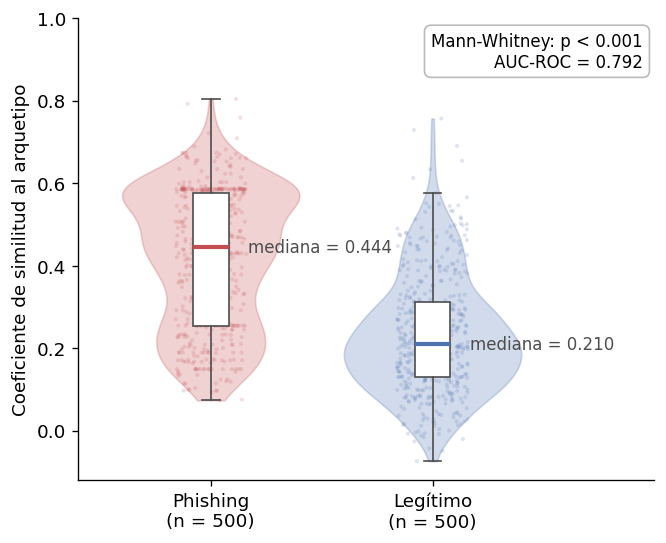

In [2]:
ph, lg = coef[y == 1], coef[y == 0]
p_clases = mannwhitneyu(ph, lg, alternative="two-sided").pvalue
auc = roc_auc_score(y, coef)
rng = np.random.default_rng(SEMILLA)

fig, ax = plt.subplots(figsize=(6.2, 5))
for x, datos, color in [(0, ph, COLOR_PHISHING), (1, lg, COLOR_LEGITIMO)]:
    violin = ax.violinplot(datos, positions=[x], widths=0.8, showextrema=False)
    for cuerpo in violin["bodies"]:
        cuerpo.set_facecolor(color)
        cuerpo.set_edgecolor(color)
        cuerpo.set_alpha(0.25)
    ax.scatter(x + rng.uniform(-0.16, 0.16, len(datos)), datos, s=6, alpha=0.18, color=color, edgecolors="none", zorder=2)
    ax.boxplot(datos, positions=[x], widths=0.16, showfliers=False, patch_artist=True, zorder=3,
               boxprops={"facecolor": "white", "edgecolor": GRIS}, medianprops={"color": color, "linewidth": 2.5},
               whiskerprops={"color": GRIS}, capprops={"color": GRIS})
    ax.annotate(f"mediana = {np.median(datos):.3f}", (x + 0.11, np.median(datos)), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=10, color=GRIS)

ax.set_xticks([0, 1])
ax.set_xticklabels([f"Phishing\n(n = {len(ph)})", f"Legítimo\n(n = {len(lg)})"])
ax.set_xlim(-0.6, 2.0)
ax.set_ylim(-0.12, 1.0)   # el coeficiente mínimo observado es ligeramente negativo
ax.set_ylabel("Coeficiente de similitud al arquetipo")
ax.text(0.98, 0.97, f"Mann-Whitney: {texto_p(p_clases)}\nAUC-ROC = {auc:.3f}", transform=ax.transAxes, ha="right", va="top",
        fontsize=10, bbox={"boxstyle": "round,pad=0.4", "facecolor": "white", "edgecolor": "#bbbbbb"})
guardar(fig, "fig_obj2_coeficiente_distribucion.png")
plt.show()

## Figura 2. Arquetipos discriminativos (lift)

Lift suavizado = [(phishing + 0.5) / (500 + 0.5)] / [(legítimos + 0.5) / (500 + 0.5)]. Un valor de 1 indica que
el arquetipo se asigna igual a ambas clases. El eje es logarítmico porque el lift es un cociente.

Arquetipos con al menos 5 correos: 10 | omitidos: 2 (Farmacia en línea (n = 4), Hipotecas y préstamos (n = 3))


clase,Phishing,Legítimo,n,lift,pct_phishing
arquetipo_nombre,,,,,
Fraude de anticipo (419),24,0,24,49.00,100.00
Verificación / suspensión de cuenta,172,37,209,4.60,82.30
Dinero fácil / lotería,25,8,33,3.00,75.76
Agrandamiento ofuscado,4,3,7,1.29,57.14
Atracción y mejora sexual,26,28,54,0.93,48.15
Spam farmacéutico / adelgazar,214,284,498,0.75,42.97
Acciones «pump and dump»,13,33,46,0.40,28.26
Medicamentos genéricos ofuscado,18,81,99,0.23,18.18
Software pirata,2,12,14,0.20,14.29


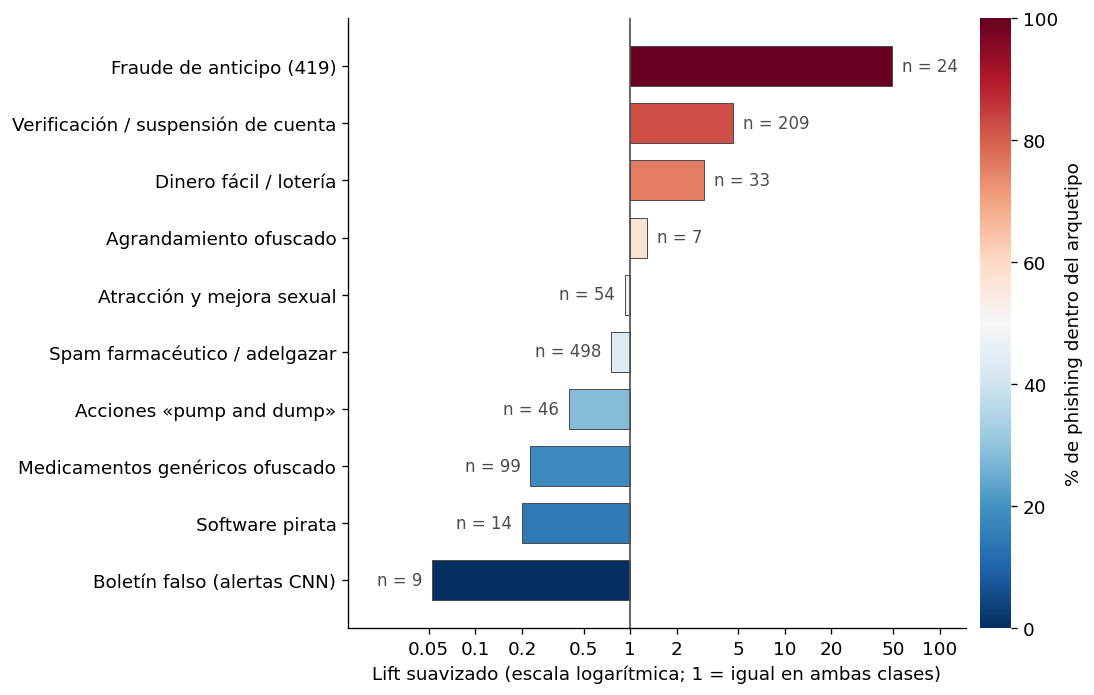

In [3]:
conteos = pd.crosstab(df["arquetipo_nombre"], df["clase"]).reindex(columns=["Phishing", "Legítimo"], fill_value=0)
conteos["n"] = conteos.sum(axis=1)
n_ph, n_lg = int(y.sum()), int((1 - y).sum())
conteos["lift"] = ((conteos["Phishing"] + 0.5) / (n_ph + 0.5)) / ((conteos["Legítimo"] + 0.5) / (n_lg + 0.5))
conteos["pct_phishing"] = conteos["Phishing"] / conteos["n"] * 100
omitidos = conteos[conteos["n"] < MIN_CORREOS]
tabla = conteos[conteos["n"] >= MIN_CORREOS].sort_values("lift")
print(f"Arquetipos con al menos {MIN_CORREOS} correos: {len(tabla)} | omitidos: {len(omitidos)} "
      f"({', '.join(f'{a} (n = {n})' for a, n in omitidos['n'].items()) or 'ninguno'})")
display(tabla.sort_values("lift", ascending=False).round(2))

# Escala divergente centrada en 50 %: azul = mayoría de legítimos, rojo = mayoría de phishing
norma = mpl.colors.TwoSlopeNorm(vmin=0, vcenter=50, vmax=100)
cmap = mpl.colormaps["RdBu_r"]

fig, ax = plt.subplots(figsize=(8, 0.5 * len(tabla) + 1.6))
pos = np.arange(len(tabla))
ax.barh(pos, tabla["lift"] - 1, left=1, color=cmap(norma(tabla["pct_phishing"])), edgecolor=GRIS, linewidth=0.6, height=0.7)
ax.axvline(1, color=GRIS, linewidth=1)
ax.set_xscale("log")
for p_, lift_, n_ in zip(pos, tabla["lift"], tabla["n"]):
    ax.annotate(f"n = {n_}", (lift_, p_), xytext=(6 if lift_ >= 1 else -6, 0), textcoords="offset points",
                ha="left" if lift_ >= 1 else "right", va="center", fontsize=10, color=GRIS)
ax.set_yticks(pos)
ax.set_yticklabels(tabla.index)
ax.set_xlim(tabla["lift"].min() / 3.5, tabla["lift"].max() * 3)
ticks = [t for t in [0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100] if ax.get_xlim()[0] <= t <= ax.get_xlim()[1]]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.set_xlabel("Lift suavizado (escala logarítmica; 1 = igual en ambas clases)")
barra = fig.colorbar(mpl.cm.ScalarMappable(norm=norma, cmap=cmap), ax=ax, pad=0.02)
barra.set_label("% de phishing dentro del arquetipo")
barra.outline.set_visible(False)
guardar(fig, "fig_obj2_lift_arquetipos.png")
plt.show()

## Figura 3. Arquetipo × clase (porcentaje dentro del arquetipo)

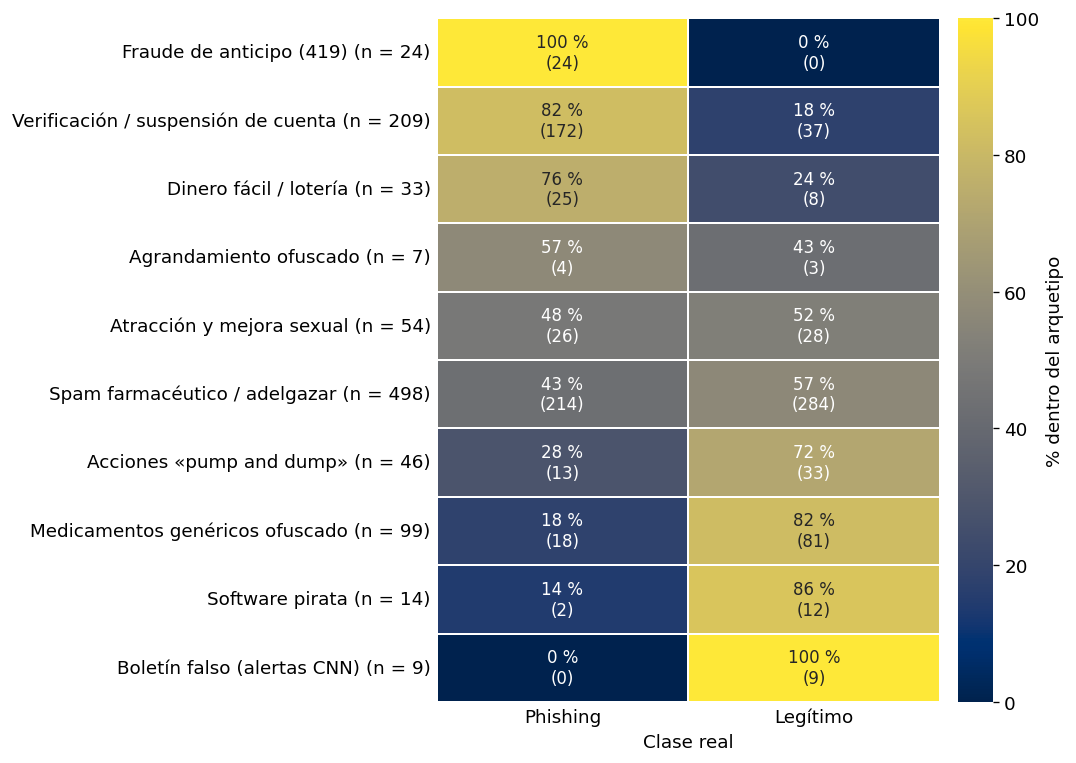

In [4]:
orden = tabla.sort_values("pct_phishing", ascending=False)
pct = orden[["Phishing", "Legítimo"]].div(orden["n"], axis=0) * 100
anotaciones = np.array([[f"{pct.iloc[i, j]:.0f} %\n({orden[['Phishing', 'Legítimo']].iloc[i, j]})" for j in range(2)] for i in range(len(orden))])

fig, ax = plt.subplots(figsize=(6.6, 0.62 * len(orden) + 1.2))
sns.heatmap(pct, annot=anotaciones, fmt="", cmap="cividis", vmin=0, vmax=100, linewidths=1, linecolor="white",
            cbar_kws={"label": "% dentro del arquetipo", "pad": 0.03}, annot_kws={"fontsize": 10}, ax=ax)
ax.set_yticklabels([f"{a} (n = {n})" for a, n in zip(orden.index, orden["n"])], rotation=0)
ax.set_xlabel("Clase real")
ax.set_ylabel("")
ax.tick_params(length=0)
ax.collections[0].colorbar.outline.set_visible(False)
guardar(fig, "fig_obj2_heatmap_arquetipos.png")
plt.show()

## Figura 4. Coeficiente en phishing detectado (TP) y no detectado (FN)

TP: n = 457, mediana 0.459 | FN: n = 43, mediana 0.247 | p < 0.001 | P(TP > FN) = 0.773


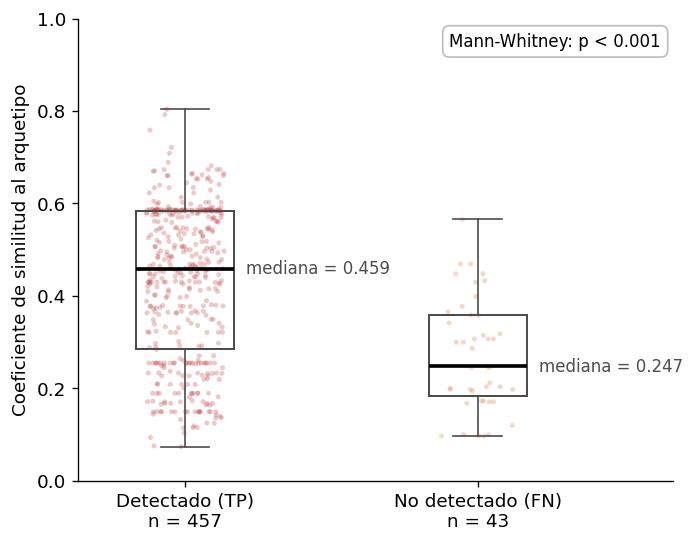

In [5]:
phishing = df[df["label"] == 1]
tp, fn = phishing.loc[phishing["detectado"], "coeficiente"].to_numpy(), phishing.loc[~phishing["detectado"], "coeficiente"].to_numpy()
u, p_tp_fn = mannwhitneyu(tp, fn, alternative="two-sided")
print(f"TP: n = {len(tp)}, mediana {np.median(tp):.3f} | FN: n = {len(fn)}, mediana {np.median(fn):.3f} | "
      f"{texto_p(p_tp_fn)} | P(TP > FN) = {u / (len(tp) * len(fn)):.3f}")

COLOR_FN = "#dd8452"
rng = np.random.default_rng(SEMILLA)
fig, ax = plt.subplots(figsize=(6.4, 5))
for x, datos, color in [(0, tp, COLOR_PHISHING), (1.5, fn, COLOR_FN)]:
    ax.scatter(x + rng.uniform(-0.2, 0.2, len(datos)), datos, s=9, alpha=0.3, color=color, edgecolors="none", zorder=2)
    ax.boxplot(datos, positions=[x], widths=0.5, showfliers=False, patch_artist=True, zorder=3,
               boxprops={"facecolor": "none", "edgecolor": GRIS, "linewidth": 1.2}, medianprops={"color": "black", "linewidth": 2.2},
               whiskerprops={"color": GRIS}, capprops={"color": GRIS})
    ax.annotate(f"mediana = {np.median(datos):.3f}", (x + 0.27, np.median(datos)), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=10, color=GRIS)
ax.set_xticks([0, 1.5])
ax.set_xticklabels([f"Detectado (TP)\nn = {len(tp)}", f"No detectado (FN)\nn = {len(fn)}"])
ax.set_xlim(-0.55, 2.5)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Coeficiente de similitud al arquetipo")
ax.text(0.98, 0.97, f"Mann-Whitney: {texto_p(p_tp_fn)}", transform=ax.transAxes, ha="right", va="top", fontsize=10,
        bbox={"boxstyle": "round,pad=0.4", "facecolor": "white", "edgecolor": "#bbbbbb"})
guardar(fig, "fig_obj2_tp_vs_fn_coeficiente.png")
plt.show()

## Figura 5. Curva ROC del coeficiente como clasificador

AUC = 0.792 (IC 95 % bootstrap, n = 1000: 0.764 a 0.821)


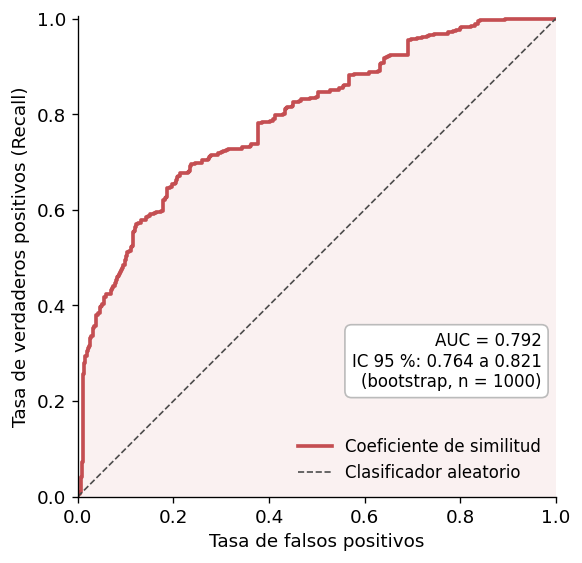

In [6]:
N_BOOTSTRAP = 1000
rng = np.random.default_rng(SEMILLA)
aucs = []
for _ in range(N_BOOTSTRAP):
    idx = rng.integers(0, len(y), len(y))
    if len(np.unique(y[idx])) == 2:
        aucs.append(roc_auc_score(y[idx], coef[idx]))
ic_inf, ic_sup = np.percentile(aucs, [2.5, 97.5])
fpr, tpr, _ = roc_curve(y, coef)
print(f"AUC = {auc:.3f} (IC 95 % bootstrap, n = {N_BOOTSTRAP}: {ic_inf:.3f} a {ic_sup:.3f})")

fig, ax = plt.subplots(figsize=(5.4, 5.2))
ax.plot(fpr, tpr, color=COLOR_PHISHING, linewidth=2.2, label="Coeficiente de similitud")
ax.fill_between(fpr, tpr, alpha=0.08, color=COLOR_PHISHING, linewidth=0)
ax.plot([0, 1], [0, 1], linestyle="--", color=GRIS, linewidth=1, label="Clasificador aleatorio")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.005)
ax.set_aspect("equal")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.text(0.97, 0.22, f"AUC = {auc:.3f}\nIC 95 %: {ic_inf:.3f} a {ic_sup:.3f}\n(bootstrap, n = {N_BOOTSTRAP})", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=10, bbox={"boxstyle": "round,pad=0.4", "facecolor": "white", "edgecolor": "#bbbbbb"})
ax.legend(frameon=False, loc="lower right")
guardar(fig, "fig_obj2_roc_coeficiente.png")
plt.show()

## Figura 6. Proporción de phishing por decil de coeficiente

Los 1,000 correos se ordenan por coeficiente y se dividen en 10 grupos de 100.

,n,phishing,coef_min,coef_max,pct_phishing
decil,,,,,
1,100,9,-0.074,0.104,9.0
2,100,29,0.104,0.153,29.0
3,100,35,0.155,0.199,35.0
4,100,32,0.200,0.246,32.0
5,100,38,0.246,0.295,38.0
6,100,47,0.295,0.374,47.0
7,100,61,0.375,0.444,61.0
8,100,68,0.446,0.507,68.0
9,100,87,0.509,0.584,87.0


,Valor,Calculada sobre
Correlación punto-biserial coeficiente–etiqueta,0.512 (p < 0.001),"1,000 correos"
Correlación de Spearman coeficiente–etiqueta,0.506 (p < 0.001),"1,000 correos"
AUC-ROC del coeficiente,0.792,"1,000 correos"
Pendiente de la recta de tendencia,+8.7 puntos porcentuales por decil (p < 0.001),10 deciles
R² de la recta de tendencia,0.945,10 deciles


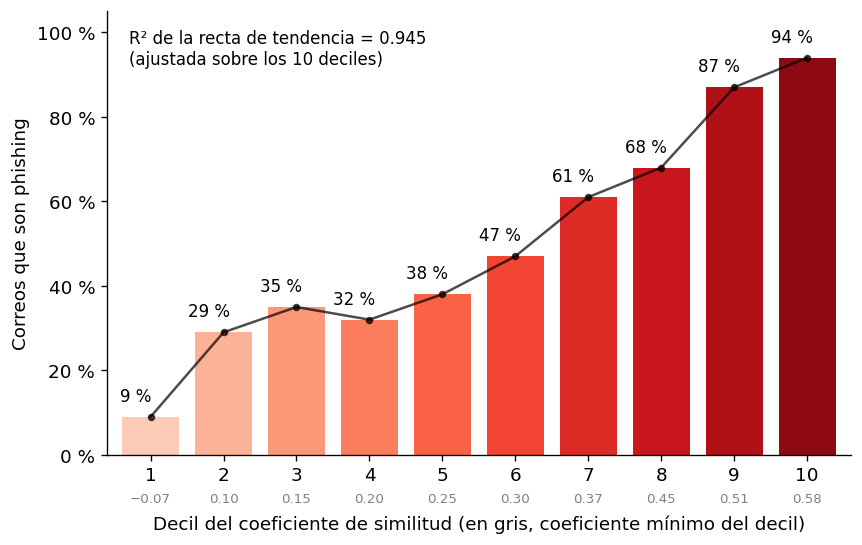

In [7]:
from matplotlib.transforms import blended_transform_factory

# Deciles del coeficiente: 10 grupos de 100 correos, del coeficiente más bajo (1) al más alto (10)
df["decil"] = pd.qcut(df["coeficiente"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
deciles = df.groupby("decil").agg(n=("label", "size"), phishing=("label", "sum"),
                                  coef_min=("coeficiente", "min"), coef_max=("coeficiente", "max"))
deciles["pct_phishing"] = deciles["phishing"] / deciles["n"] * 100
display(deciles.round(3))

# Métricas que acompañan la figura: asociación entre el coeficiente y la etiqueta real
from scipy.stats import linregress, pearsonr, spearmanr

r_pb, p_pb = pearsonr(df["coeficiente"], df["label"])        # punto-biserial, sobre los 1,000 correos
rho_s, p_s = spearmanr(df["coeficiente"], df["label"])       # Spearman, sobre los 1,000 correos
auc_coef = roc_auc_score(df["label"], df["coeficiente"])
tendencia = linregress(deciles.index, deciles["pct_phishing"])  # recta sobre los 10 deciles
metricas_f6 = pd.DataFrame({
    "Valor": [f"{r_pb:.3f} ({texto_p(p_pb)})", f"{rho_s:.3f} ({texto_p(p_s)})", f"{auc_coef:.3f}",
              f"+{tendencia.slope:.1f} puntos porcentuales por decil ({texto_p(tendencia.pvalue)})", f"{tendencia.rvalue ** 2:.3f}"],
    "Calculada sobre": ["1,000 correos", "1,000 correos", "1,000 correos", "10 deciles", "10 deciles"],
}, index=["Correlación punto-biserial coeficiente–etiqueta", "Correlación de Spearman coeficiente–etiqueta", "AUC-ROC del coeficiente",
          "Pendiente de la recta de tendencia", "R² de la recta de tendencia"])
display(metricas_f6)

colores = mpl.colormaps["Reds"](np.linspace(0.2, 0.92, len(deciles)))  # de claro (decil 1) a oscuro (decil 10)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(deciles.index, deciles["pct_phishing"], color=colores, width=0.78, zorder=2)
ax.plot(deciles.index, deciles["pct_phishing"], color="black", linewidth=1.5, alpha=0.7, marker="o", markersize=3.5, zorder=3)
for d, pct in deciles["pct_phishing"].items():
    ax.annotate(f"{pct:.0f} %", (d, pct), xytext=(-9, 7), textcoords="offset points", ha="center", va="bottom", fontsize=10)  # arriba a la izquierda, sin tapar la línea

ax.set_xticks(deciles.index)
ax.set_xticklabels(deciles.index)
mixta_x = blended_transform_factory(ax.transData, ax.transAxes)
for d, minimo in deciles["coef_min"].items():  # límite inferior de coeficiente de cada decil
    ax.text(d, -0.085, f"{minimo:.2f}".replace("-", "−"), transform=mixta_x, ha="center", va="top", fontsize=8, color="gray")
ax.set_xlim(0.4, 10.6)
ax.set_ylim(0, 105)
ax.set_yticks(range(0, 101, 20))
ax.set_yticklabels([f"{v} %" for v in range(0, 101, 20)])
ax.set_xlabel("Decil del coeficiente de similitud (en gris, coeficiente mínimo del decil)", labelpad=18)
ax.set_ylabel("Correos que son phishing")
anotacion = f"R² de la recta de tendencia = {tendencia.rvalue ** 2:.3f}" + chr(10) + "(ajustada sobre los 10 deciles)"
ax.text(0.03, 0.96, anotacion, transform=ax.transAxes, ha="left", va="top", fontsize=10)
guardar(fig, "fig_obj2_deciles_v2.png")
plt.show()

## Figura 7. Proporción de phishing en una ventana deslizante

Misma relación que la figura 6, sin cortes fijos: los correos se ordenan por coeficiente y se calcula la proporción de phishing en cada grupo consecutivo de 80, avanzando de uno en uno. Las ventanas vecinas comparten 79 correos, así que la curva es una descripción suavizada, no una serie de estimaciones independientes.

Rango del coeficiente: -0.07 a 0.80 | rango de la curva (medianas de ventana): 0.05 a 0.61
Ventanas: 921 | Spearman rho = 0.506 (p < 0.001)
Proporción en la ventana: mínimo 2.5 % (coeficiente 0.05), máximo 100.0 % (coeficiente 0.58)


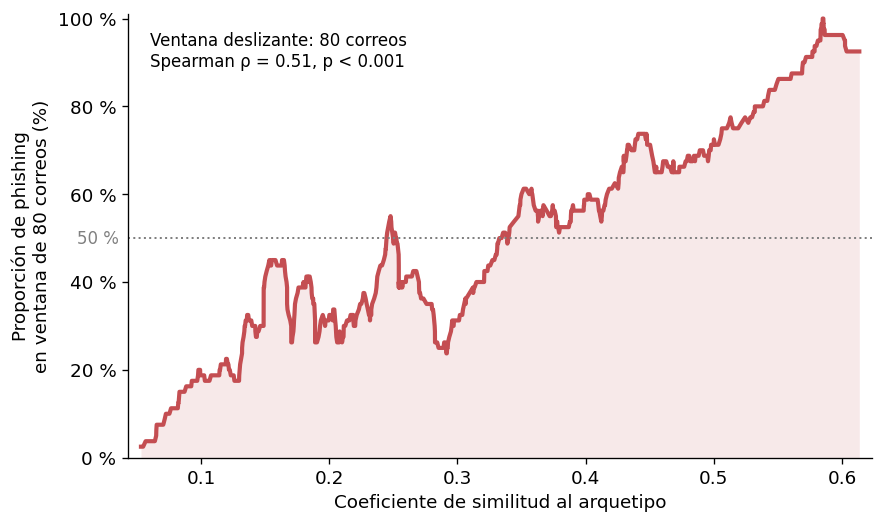

In [8]:
from scipy.stats import spearmanr

VENTANA = 80
ordenado = df.sort_values("coeficiente", kind="mergesort")
x_ventana = ordenado["coeficiente"].rolling(VENTANA).median().dropna().to_numpy()   # mediana del coeficiente en la ventana
y_ventana = ordenado["label"].rolling(VENTANA).mean().dropna().to_numpy() * 100     # % de phishing en la ventana
rho, p_rho = spearmanr(df["coeficiente"], df["label"])  # sobre los 1,000 correos, antes de suavizar
print(f"Rango del coeficiente: {df['coeficiente'].min():.2f} a {df['coeficiente'].max():.2f} | rango de la curva (medianas de ventana): {x_ventana.min():.2f} a {x_ventana.max():.2f}")
print(f"Ventanas: {len(x_ventana)} | Spearman rho = {rho:.3f} ({texto_p(p_rho)})")
print(f"Proporción en la ventana: mínimo {y_ventana.min():.1f} % (coeficiente {x_ventana[y_ventana.argmin()]:.2f}), "
      f"máximo {y_ventana.max():.1f} % (coeficiente {x_ventana[y_ventana.argmax()]:.2f})")

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.fill_between(x_ventana, y_ventana, color=COLOR_PHISHING, alpha=0.12, linewidth=0)
ax.plot(x_ventana, y_ventana, color=COLOR_PHISHING, linewidth=2.5)
ax.axhline(50, linestyle=":", color="gray", linewidth=1.2)
ax.text(-0.012, 50, "50 %", transform=blended_transform_factory(ax.transAxes, ax.transData), ha="right", va="center",
        fontsize=10, color="gray")
# La mediana de una ventana de 80 correos no llega a los extremos del coeficiente; el eje cubre el rango de la curva
ax.set_xlim(x_ventana.min() - 0.01, x_ventana.max() + 0.01)
ax.set_ylim(0, 101)
ax.set_yticks(range(0, 101, 20))
ax.set_yticklabels([f"{v} %" for v in range(0, 101, 20)])
ax.set_xlabel("Coeficiente de similitud al arquetipo")
ax.set_ylabel(f"Proporción de phishing\nen ventana de {VENTANA} correos (%)")
ax.text(0.03, 0.96, f"Ventana deslizante: {VENTANA} correos\nSpearman ρ = {rho:.2f}, {texto_p(p_rho)}", transform=ax.transAxes,
        ha="left", va="top", fontsize=10)
guardar(fig, "fig_obj2_curva_suavizada.png")
plt.show()

In [9]:
print("Figuras guardadas:")
for ruta in figuras_guardadas:
    print(" ", ruta)

print()
print("Figuras nuevas (6 y 7):")
for ruta in figuras_guardadas[-2:]:
    print(" ", ruta)

Figuras guardadas:
  C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion\experiments\figures\arquetipos_objetivo2\fig_obj2_coeficiente_distribucion.png
  C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion\experiments\figures\arquetipos_objetivo2\fig_obj2_lift_arquetipos.png
  C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion\experiments\figures\arquetipos_objetivo2\fig_obj2_heatmap_arquetipos.png
  C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion\experiments\figures\arquetipos_objetivo2\fig_obj2_tp_vs_fn_coeficiente.png
  C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segundo Semestre\Tesis\Trabajo-de-Graduacion\experiments\figures\arquetipos_objetivo2\fig_obj2_roc_coeficiente.png
  C:\Users\50250\Desktop\Sofía Mishell Velásquez UVG\Quinto año\Segun